
## Klasifikasi Risiko Gagal Bayar Nasabah Kartu Kredit

**Kelompok: A07**

Mirawati Hutasoit (231110639)

Saskia Anggi Pratiwi (231110909)

Ade Kurnia Setialu (231110333)


**Dataset:** Default of Credit Card Clients (UCI Machine Learning Repository), diunduh otomatis dari tautan di bawah (tanpa file CSV lokal).

**Cara menjalankan:** buka di Google Colab atau Jupyter, lalu **Runtime > Run all**. Butuh koneksi internet (untuk mengunduh dataset). Tidak perlu mengunggah file apa pun. Seluruh hasil memakai `random_state=42` sehingga dapat direproduksi. Semua angka di laporan PDF diambil dari keluaran notebook ini dan dari folder `results/` (`summary.json` dan file CSV).



In [ ]:
import sys, subprocess, importlib, os, json, time, platform, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

try:
    display
except NameError:
    display = print

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42
TARGET = "default"
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
R = {}   # semua angka penting dikumpulkan di sini lalu disimpan ke results/summary.json

# Daftar kolom (nama mengikuti dokumentasi UCI; PAY_0 diganti PAY_1 agar urutan 1..6 konsisten)
PAY_COLS  = [f"PAY_{i}" for i in range(1, 7)]
BILL_COLS = [f"BILL_AMT{i}" for i in range(1, 7)]
PAMT_COLS = [f"PAY_AMT{i}" for i in range(1, 7)]
LIST_KATEGORIK = ["SEX", "EDUCATION", "MARRIAGE"]
FEATURES = ["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"] + PAY_COLS + BILL_COLS + PAMT_COLS
NEW_FEATS = ["n_late_months", "max_delay", "utilization", "pay_ratio", "avg_bill", "avg_pay_amt"]
print("Setup selesai | scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

Setup selesai | scikit-learn 1.6.1 | pandas 2.2.3


# B. Dataset dan Data Understanding

**Sumber.** UCI Machine Learning Repository, *Default of Credit Card Clients* (Yeh & Lien, 2009; donor: I-Cheng Yeh).
- Halaman dataset: <https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients>
- Berkas unduhan langsung (cadangan): <https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip>


In [ ]:
UCI_PAGE = "https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients"
UCI_ZIP  = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"

RENAME_UCIML = {"X1": "LIMIT_BAL", "X2": "SEX", "X3": "EDUCATION", "X4": "MARRIAGE", "X5": "AGE",
                "X6": "PAY_1", "X7": "PAY_2", "X8": "PAY_3", "X9": "PAY_4", "X10": "PAY_5", "X11": "PAY_6",
                "X12": "BILL_AMT1", "X13": "BILL_AMT2", "X14": "BILL_AMT3",
                "X15": "BILL_AMT4", "X16": "BILL_AMT5", "X17": "BILL_AMT6",
                "X18": "PAY_AMT1", "X19": "PAY_AMT2", "X20": "PAY_AMT3",
                "X21": "PAY_AMT4", "X22": "PAY_AMT5", "X23": "PAY_AMT6"}

def load_from_ucimlrepo():
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=350)
    X = ds.data.features.copy()
    y = ds.data.targets.iloc[:, 0].rename(TARGET)
    return pd.concat([X, y], axis=1)

def load_from_zip():
    import io, zipfile, urllib.request
    blob = urllib.request.urlopen(UCI_ZIP, timeout=120).read()
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        name = [n for n in z.namelist() if n.lower().endswith((".xls", ".xlsx"))][0]
        d = pd.read_excel(io.BytesIO(z.read(name)), header=1)
    d = d.rename(columns={"default payment next month": TARGET})
    return d.drop(columns=[c for c in ["ID"] if c in d.columns])

try:
    raw = load_from_ucimlrepo(); sumber = "ucimlrepo (id=350)"
except Exception as e:
    print("ucimlrepo gagal:", repr(e)[:120], "-> memakai unduhan .zip UCI")
    raw = load_from_zip(); sumber = "unduhan .zip UCI"

# Samakan nama kolom dari kedua jalur pemuatan
raw = raw.rename(columns=RENAME_UCIML).rename(columns={"PAY_0": "PAY_1"})
raw = raw[FEATURES + [TARGET]].astype("int64")
assert raw.shape == (30000, 24), f"Bentuk data tidak sesuai harapan: {raw.shape}"

print("Sumber data       :", sumber)
print("Jumlah observasi  :", raw.shape[0])
print("Jumlah fitur      :", raw.shape[1] - 1, "(+ 1 target)")
R.update(sumber_data=sumber, uci_page=UCI_PAGE, n_rows_raw=int(raw.shape[0]), n_features=int(raw.shape[1] - 1))
raw.head()

ucimlrepo gagal: ModuleNotFoundError("No module named 'ucimlrepo'") -> memakai unduhan .zip UCI
Sumber data       : unduhan .zip UCI
Jumlah observasi  : 30000
Jumlah fitur      : 23 (+ 1 target)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [ ]:
# Kualitas data: tipe, nilai unik, missing value, duplikat, statistik deskriptif
tipe = pd.DataFrame({"Tipe data": raw.dtypes.astype(str), "Nilai unik": raw.nunique(), "Contoh (baris 1)": raw.iloc[0]})
tipe.to_csv("results/tipe_data_fitur.csv")
display(tipe)
print("\nStatistik deskriptif:")
display(raw.describe().T.round(2))

n_missing  = int(raw.isna().sum().sum())
n_dup_rows = int(raw.duplicated().sum())
print(f"\nMissing value total : {n_missing}")
print(f"Baris duplikat      : {n_dup_rows} ({n_dup_rows / len(raw) * 100:.2f}% dari data)")
R.update(n_missing=n_missing, n_dup_rows=n_dup_rows)

,Tipe data,Nilai unik,Contoh (baris 1)
LIMIT_BAL,int64,81,20000
SEX,int64,2,2
EDUCATION,int64,7,2
MARRIAGE,int64,4,1
AGE,int64,56,24
PAY_1,int64,11,2
PAY_2,int64,11,2
PAY_3,int64,11,-1
PAY_4,int64,11,-1
PAY_5,int64,10,-2



Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.60,0.49,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.85,0.79,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.55,0.52,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.49,9.22,21.0,28.00,34.0,41.00,79.0
PAY_1,30000.0,-0.02,1.12,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.13,1.20,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.17,1.20,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.22,1.17,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.27,1.13,-2.0,-1.00,0.0,0.00,8.0



Missing value total : 0
Baris duplikat      : 35 (0.12% dari data)


In [ ]:
# Nilai kategori yang tidak sesuai dokumentasi
for c in LIST_KATEGORIK:
    print(c, raw[c].value_counts().sort_index().to_dict())
print("PAY_1:", raw["PAY_1"].value_counts().sort_index().to_dict())

R["edu_invalid"] = int(raw["EDUCATION"].isin([0, 5, 6]).sum())
R["mar_invalid"] = int((raw["MARRIAGE"] == 0).sum())
R["pay_undoc_cells"] = int(raw[PAY_COLS].isin([-2, 0]).sum().sum())
R["neg_bill_cells"] = int((raw[BILL_COLS] < 0).sum().sum())
print(f"\nEDUCATION bernilai 0/5/6 (tidak terdokumentasi): {R['edu_invalid']} baris")
print(f"MARRIAGE bernilai 0 (tidak terdokumentasi)     : {R['mar_invalid']} baris")
print(f"Sel PAY_* bernilai -2 atau 0                     : {R['pay_undoc_cells']} sel")
print(f"Sel BILL_AMT bernilai negatif                    : {R['neg_bill_cells']} sel")

SEX {1: 11888, 2: 18112}
EDUCATION {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE {0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_1: {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}

EDUCATION bernilai 0/5/6 (tidak terdokumentasi): 345 baris
MARRIAGE bernilai 0 (tidak terdokumentasi)     : 54 baris
Sel PAY_* bernilai -2 atau 0                     : 120334 sel
Sel BILL_AMT bernilai negatif                    : 3932 sel


In [ ]:
# Outlier dan kemiringan (skewness) pada fitur nominal uang
amount_raw = ["LIMIT_BAL"] + BILL_COLS + PAMT_COLS
rows = []
for c in amount_raw + ["AGE"]:
    q1, q3 = raw[c].quantile([0.25, 0.75]); iqr = q3 - q1
    out = ((raw[c] < q1 - 1.5 * iqr) | (raw[c] > q3 + 1.5 * iqr)).mean() * 100
    rows.append({"Fitur": c, "Median": raw[c].median(), "Maks": raw[c].max(),
                 "Skewness": raw[c].skew(), "% di luar 1,5xIQR": out})
outlier_df = pd.DataFrame(rows).set_index("Fitur").round(2)
outlier_df.to_csv("results/outlier_summary.csv")
R["skew_max"] = float(outlier_df["Skewness"].max())
display(outlier_df)

,Median,Maks,Skewness,"% di luar 1,5xIQR"
Fitur,,,,
LIMIT_BAL,140000.0,1000000,0.99,0.56
BILL_AMT1,22381.5,964511,2.66,8.00
BILL_AMT2,21200.0,983931,2.71,7.98
BILL_AMT3,20088.5,1664089,3.09,8.23
BILL_AMT4,19052.0,891586,2.82,8.74
BILL_AMT5,18104.5,927171,2.88,9.08
BILL_AMT6,17071.0,961664,2.85,8.98
PAY_AMT1,2100.0,873552,14.67,9.15
PAY_AMT2,2009.0,1684259,30.45,9.05


In [ ]:
# Ringkasan temuan data understanding (dihitung otomatis dari output di atas)
print("TEMUAN DATA UNDERSTANDING")
print(f"1. Data berisi {R['n_rows_raw']:,} nasabah dan {R['n_features']} fitur; tidak ada missing value ({R['n_missing']}).")
print(f"2. Ada {R['n_dup_rows']} baris duplikat persis (tanpa ID). Jumlahnya sangat kecil, tetapi tetap dihapus agar baris yang sama tidak muncul di train dan test.")
print(f"3. Kode kategori tidak terdokumentasi: EDUCATION 0/5/6 = {R['edu_invalid']} baris, MARRIAGE 0 = {R['mar_invalid']} baris. Digabung ke kategori 'lainnya'.")
print(f"4. PAY_* memuat nilai -2 dan 0 yang tidak ada di dokumentasi ({R['pay_undoc_cells']:,} sel). Tetap diperlakukan sebagai skala ordinal numerik apa adanya.")
print(f"5. Fitur uang sangat miring ke kanan (skewness maksimum {R['skew_max']:.1f}) dan ada {R['neg_bill_cells']} sel tagihan negatif (kelebihan bayar).")

TEMUAN DATA UNDERSTANDING
1. Data berisi 30,000 nasabah dan 23 fitur; tidak ada missing value (0).
2. Ada 35 baris duplikat persis (tanpa ID). Jumlahnya sangat kecil, tetapi tetap dihapus agar baris yang sama tidak muncul di train dan test.
3. Kode kategori tidak terdokumentasi: EDUCATION 0/5/6 = 345 baris, MARRIAGE 0 = 54 baris. Digabung ke kategori 'lainnya'.
4. PAY_* memuat nilai -2 dan 0 yang tidak ada di dokumentasi (120,334 sel). Tetap diperlakukan sebagai skala ordinal numerik apa adanya.
5. Fitur uang sangat miring ke kanan (skewness maksimum 30.4) dan ada 3932 sel tagihan negatif (kelebihan bayar).


**Interpretasi data understanding.**
- Kualitas dasar data baik (tanpa nilai hilang), tetapi ada tiga masalah yang perlu ditangani: **kode kategori tidak terdokumentasi**, **duplikat** dalam jumlah kecil, dan **fitur uang yang sangat miring dengan banyak outlier** menurut aturan IQR.
- Outlier pada tagihan dan pembayaran bukan kesalahan input: itu nasabah dengan transaksi besar. Karena itu outlier **tidak dihapus**, tetapi skalanya dikompres dengan transformasi log bertanda (lihat bagian D).
- Makna `PAY_* = -2` dan `0` tidak dijelaskan dokumentasi. Kami mempertahankannya sebagai skala ordinal dan mencatatnya sebagai keterbatasan interpretasi.

# C. EDA dan Initial Findings



Baris setelah pembersihan: 29965 | baris duplikat dihapus: 35
         jumlah  persen
default                
0         23335   77.87
1          6630   22.13


/tmp/ipykernel_13345/3539616878.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Risiko rendah (0)", "Risiko tinggi (1)"], y=vc.values, palette=["#4C9F70", "#D9534F"], ax=ax)


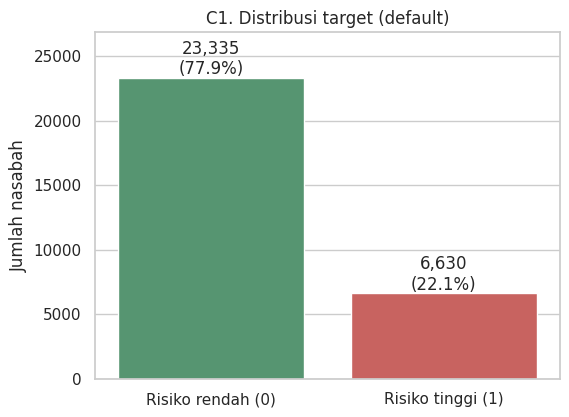

Rasio mayoritas : minoritas = 3.52 : 1
Akurasi model yang selalu menebak kelas 0 = 77.87%


In [ ]:
# Pembersihan awal untuk EDA (aturan tetap, dijelaskan di bagian D)
df = raw.copy()
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
R["n_dup_removed"] = int(before - len(df)); R["n_rows_clean"] = int(len(df))
print("Baris setelah pembersihan:", len(df), "| baris duplikat dihapus:", R["n_dup_removed"])

# C1. Distribusi target
vc = df[TARGET].value_counts().sort_index()
pct = df[TARGET].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"jumlah": vc, "persen": pct.round(2)}))
R.update(n_class0=int(vc[0]), n_class1=int(vc[1]), pct_class1=float(pct[1]),
         rasio_kelas=float(vc[0] / vc[1]))
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.barplot(x=["Risiko rendah (0)", "Risiko tinggi (1)"], y=vc.values, palette=["#4C9F70", "#D9534F"], ax=ax)
for i, (c, p) in enumerate(zip(vc.values, pct.values)):
    ax.text(i, c + 250, f"{c:,}\n({p:.1f}%)", ha="center")
ax.set_ylim(0, vc.max() * 1.15); ax.set_title("C1. Distribusi target (default)"); ax.set_ylabel("Jumlah nasabah")
plt.savefig("figures/01_distribusi_target.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Rasio mayoritas : minoritas = {R['rasio_kelas']:.2f} : 1")
print(f"Akurasi model yang selalu menebak kelas 0 = {pct[0]:.2f}%")

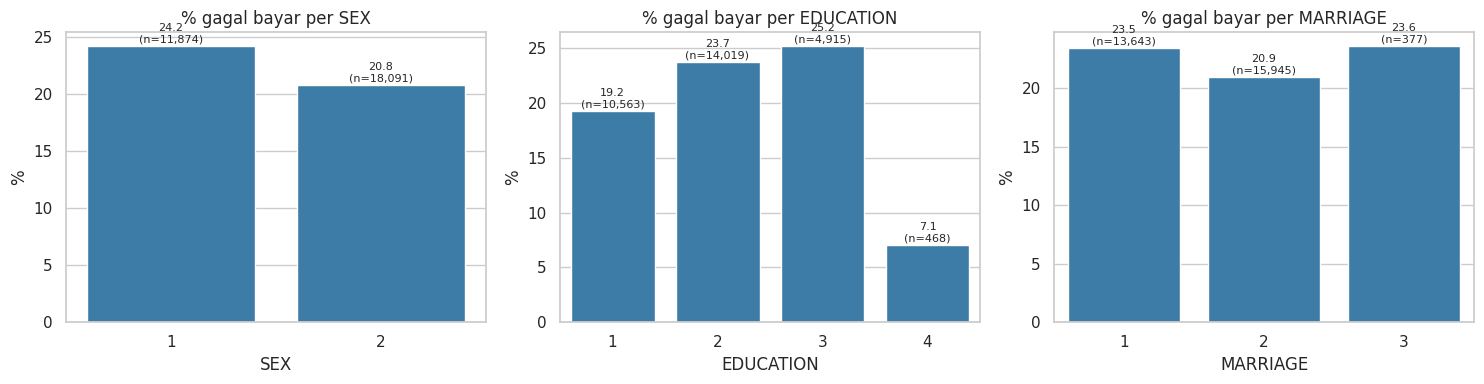

SEX      : {1: 24.2, 2: 20.8}
EDUCATION: {1: 19.2, 2: 23.7, 3: 25.2, 4: 7.1}
MARRIAGE : {1: 23.5, 2: 20.9, 3: 23.6}


In [ ]:
# C2. Tingkat gagal bayar per kategori demografi
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, LIST_KATEGORIK):
    g = df.groupby(col)[TARGET].agg(["mean", "size"])
    sns.barplot(x=g.index, y=g["mean"] * 100, ax=ax, color="#2c7fb8")
    ax.set_title(f"% gagal bayar per {col}"); ax.set_ylabel("%")
    for i, (m, n) in enumerate(zip(g["mean"] * 100, g["size"])):
        ax.text(i, m + 0.3, f"{m:.1f}\n(n={n:,})", ha="center", fontsize=8)
plt.tight_layout(); plt.savefig("figures/02_risiko_per_demografi.png", dpi=150, bbox_inches="tight"); plt.show()
R["rate_sex"] = {int(k): float(v * 100) for k, v in df.groupby("SEX")[TARGET].mean().items()}
R["rate_edu"] = {int(k): float(v * 100) for k, v in df.groupby("EDUCATION")[TARGET].mean().items()}
R["rate_mar"] = {int(k): float(v * 100) for k, v in df.groupby("MARRIAGE")[TARGET].mean().items()}
print("SEX      :", {k: round(v, 1) for k, v in R["rate_sex"].items()})
print("EDUCATION:", {k: round(v, 1) for k, v in R["rate_edu"].items()})
print("MARRIAGE :", {k: round(v, 1) for k, v in R["rate_mar"].items()})

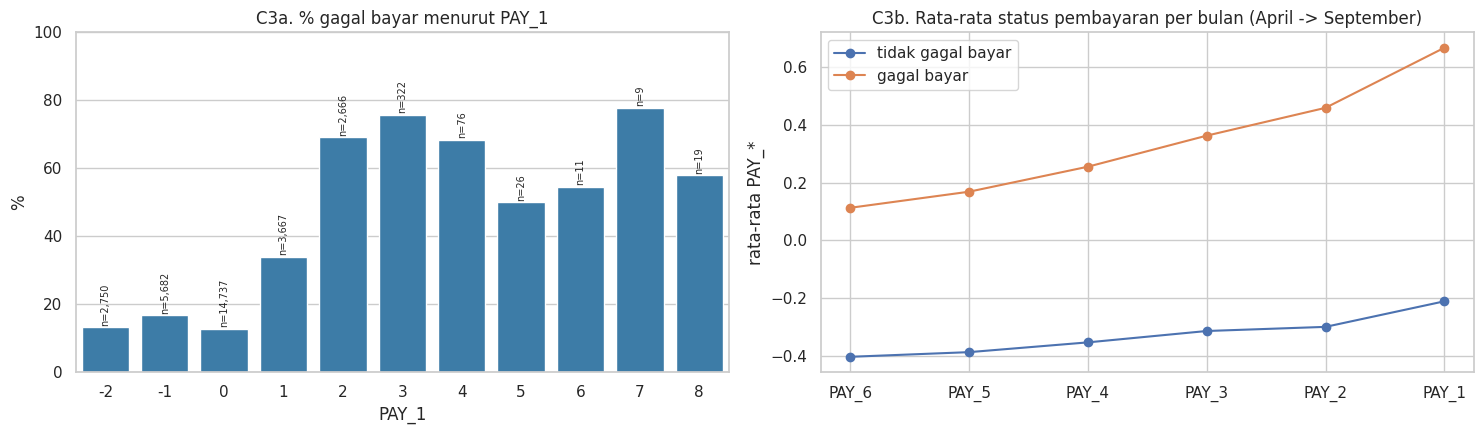

PAY_1,-2,-1,0,1,2,3,4,5,6,7,8
mean,13.24,16.79,12.81,34.03,69.13,75.78,68.42,50.0,54.55,77.78,57.89
size,2750.00,5682.00,14737.00,3667.00,2666.00,322.00,76.00,26.0,11.00,9.00,19.00


In [ ]:
# C3. Status pembayaran bulan terakhir (PAY_1) vs gagal bayar, dan riwayat keterlambatan per kelas
g = df.groupby("PAY_1")[TARGET].agg(["mean", "size"]); g["mean"] *= 100
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(x=g.index, y=g["mean"].values, color="#2c7fb8", ax=axes[0])
for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
    axes[0].text(i, m + 1, f"n={n:,}", ha="center", fontsize=7, rotation=90)
axes[0].set_ylim(0, 100); axes[0].set_title("C3a. % gagal bayar menurut PAY_1"); axes[0].set_ylabel("%")

order = PAY_COLS[::-1]   # PAY_6 (April) sampai PAY_1 (September)
for k, lab in [(0, "tidak gagal bayar"), (1, "gagal bayar")]:
    axes[1].plot(order, df.loc[df[TARGET] == k, order].mean().values, marker="o", label=lab)
axes[1].set_title("C3b. Rata-rata status pembayaran per bulan (April -> September)")
axes[1].set_ylabel("rata-rata PAY_*"); axes[1].legend()
plt.tight_layout(); plt.savefig("figures/03_risiko_per_pay1.png", dpi=150, bbox_inches="tight"); plt.show()
display(g.round(2).T)
late = df["PAY_1"] >= 1
R["rate_pay1_late"] = float(df.loc[late, TARGET].mean() * 100)
R["rate_pay1_notlate"] = float(df.loc[~late, TARGET].mean() * 100)
R["pct_late_pay1"] = float(late.mean() * 100)
late2 = df["PAY_1"] >= 2
R["rate_pay1_ge2"] = float(df.loc[late2, TARGET].mean() * 100)

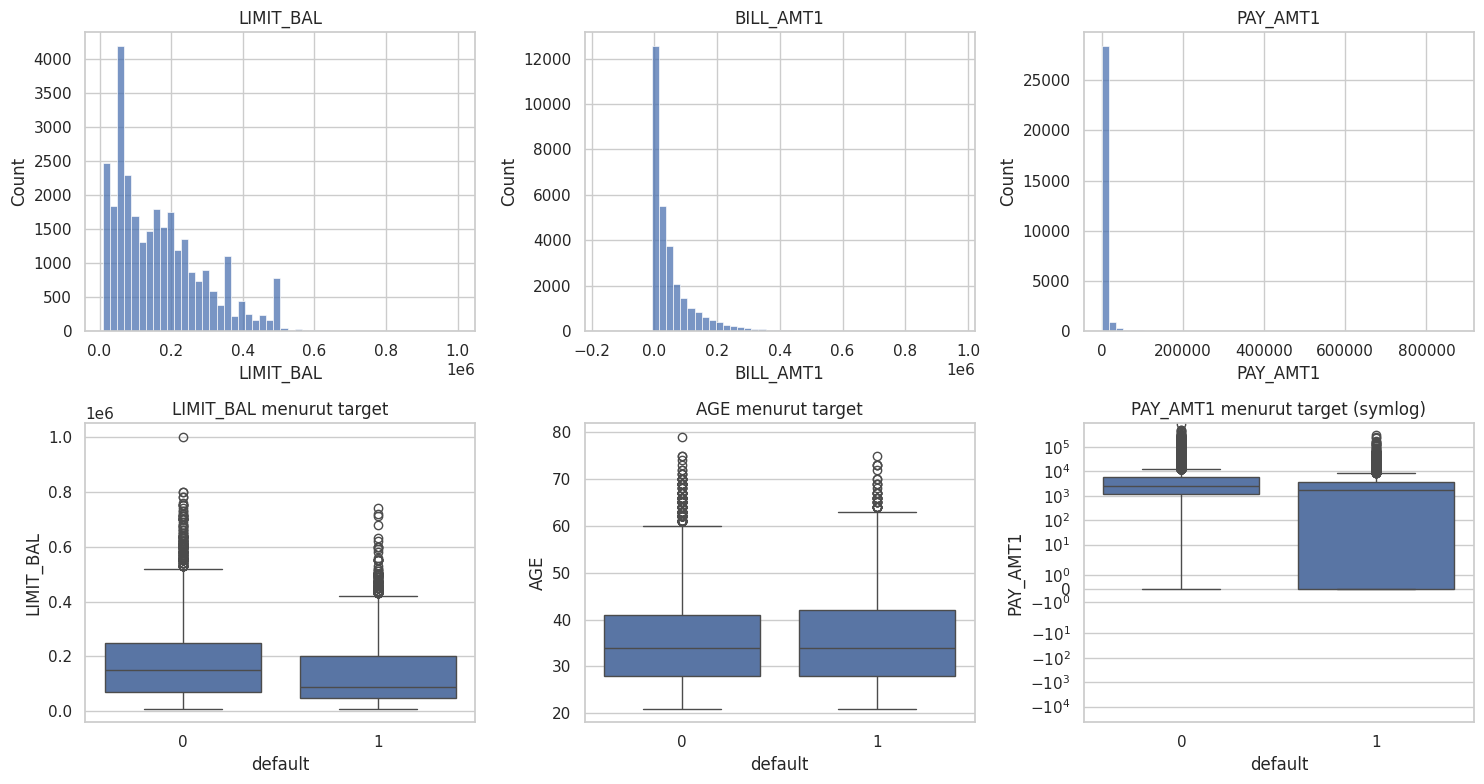

In [ ]:
# C4. Distribusi fitur uang dan perbandingan antar kelas
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.histplot(df["LIMIT_BAL"], bins=50, ax=axes[0, 0]); axes[0, 0].set_title("LIMIT_BAL")
sns.histplot(df["BILL_AMT1"], bins=50, ax=axes[0, 1]); axes[0, 1].set_title("BILL_AMT1")
sns.histplot(df["PAY_AMT1"], bins=50, ax=axes[0, 2]); axes[0, 2].set_title("PAY_AMT1")
sns.boxplot(x=TARGET, y="LIMIT_BAL", data=df, ax=axes[1, 0]); axes[1, 0].set_title("LIMIT_BAL menurut target")
sns.boxplot(x=TARGET, y="AGE", data=df, ax=axes[1, 1]); axes[1, 1].set_title("AGE menurut target")
sns.boxplot(x=TARGET, y="PAY_AMT1", data=df, ax=axes[1, 2]); axes[1, 2].set_yscale("symlog"); axes[1, 2].set_title("PAY_AMT1 menurut target (symlog)")
plt.tight_layout(); plt.savefig("figures/04_distribusi_fitur.png", dpi=150, bbox_inches="tight"); plt.show()
R["median_limit_c0"] = float(df.loc[df[TARGET] == 0, "LIMIT_BAL"].median())
R["median_limit_c1"] = float(df.loc[df[TARGET] == 1, "LIMIT_BAL"].median())
R["median_payamt1_c0"] = float(df.loc[df[TARGET] == 0, "PAY_AMT1"].median())
R["median_payamt1_c1"] = float(df.loc[df[TARGET] == 1, "PAY_AMT1"].median())

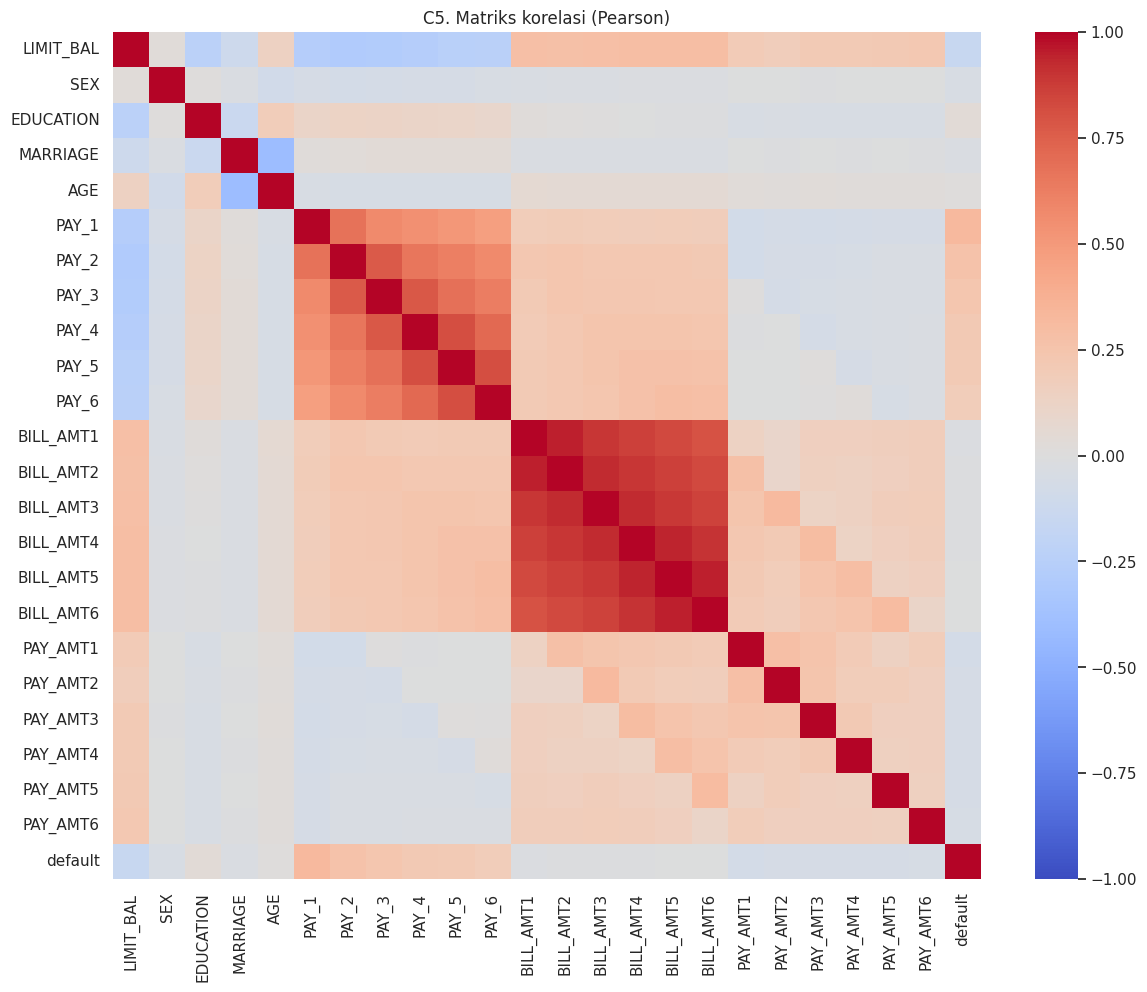

Korelasi fitur dengan target (urut mutlak):


,korelasi dgn default
PAY_1,0.325
PAY_2,0.264
PAY_3,0.235
PAY_4,0.217
PAY_5,0.204
PAY_6,0.187
LIMIT_BAL,-0.154
PAY_AMT1,-0.073
PAY_AMT2,-0.059
PAY_AMT4,-0.057


Korelasi antar BILL_AMT1..6 : 0.80 sampai 0.95
Korelasi antar PAY_1..6     : 0.48 sampai 0.82


In [ ]:
# C5. Korelasi
corr = df.corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("C5. Matriks korelasi (Pearson)")
plt.savefig("figures/05_korelasi.png", dpi=150, bbox_inches="tight"); plt.show()

corr_t = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
iu = np.triu_indices(6, 1)
R["top_corr"] = {k: float(v) for k, v in corr_t.head(7).items()}
R["bill_corr_min"] = float(corr.loc[BILL_COLS, BILL_COLS].values[iu].min())
R["bill_corr_max"] = float(corr.loc[BILL_COLS, BILL_COLS].values[iu].max())
R["pay_corr_min"] = float(corr.loc[PAY_COLS, PAY_COLS].values[iu].min())
R["pay_corr_max"] = float(corr.loc[PAY_COLS, PAY_COLS].values[iu].max())
print("Korelasi fitur dengan target (urut mutlak):")
display(corr_t.head(10).round(3).to_frame("korelasi dgn default"))
print(f"Korelasi antar BILL_AMT1..6 : {R['bill_corr_min']:.2f} sampai {R['bill_corr_max']:.2f}")
print(f"Korelasi antar PAY_1..6     : {R['pay_corr_min']:.2f} sampai {R['pay_corr_max']:.2f}")

In [ ]:
# Temuan awal EDA (dihitung otomatis dari data yang ditampilkan di atas)
t = R["top_corr"]                                   # 7 korelasi terbesar dengan target (urut nilai mutlak)
r_max = max(abs(v) for v in corr_t.values)          # korelasi mutlak tertinggi di seluruh fitur asli
n_edu4 = int((df["EDUCATION"] == 4).sum())

print("TEMUAN AWAL EDA")
print(f"1. Kelas tidak seimbang: {R['pct_class1']:.2f}% nasabah gagal bayar (rasio {R['rasio_kelas']:.2f} : 1). "
      f"Model yang selalu menebak 'tidak gagal bayar' sudah akurat {100 - R['pct_class1']:.2f}% tanpa mendeteksi satu pun nasabah berisiko -> Accuracy tidak cukup.")

print(f"2. Status pembayaran terakhir adalah sinyal terkuat: gagal bayar {R['rate_pay1_late']:.1f}% pada nasabah yang terlambat "
      f"(PAY_1 >= 1; {R['pct_late_pay1']:.1f}% populasi) vs {R['rate_pay1_notlate']:.1f}% pada yang tidak terlambat. "
      f"Untuk keterlambatan >= 2 bulan: {R['rate_pay1_ge2']:.1f}%.")

print("3. Korelasi dengan target tertinggi: " + ", ".join(f"{k} ({v:+.3f})" for k, v in list(t.items())[:4])
      + f". Korelasi mutlak tertinggi hanya {r_max:.3f}"
      + (" (di bawah 0,4): tidak ada satu fitur asli yang cukup menjelaskan target." if r_max < 0.4
         else ": ada fitur dengan hubungan linear yang cukup kuat."))

print(f"4. LIMIT_BAL berkorelasi negatif lemah ({corr_t.get('LIMIT_BAL', float('nan')):+.3f}); "
      f"median batas kredit kelas gagal bayar NT${R['median_limit_c1']:,.0f} vs NT${R['median_limit_c0']:,.0f} pada kelas lainnya.")

print(f"5. BILL_AMT1..6 sangat redundan (korelasi {R['bill_corr_min']:.2f}-{R['bill_corr_max']:.2f}); "
      f"PAY_1..6 juga saling berkorelasi ({R['pay_corr_min']:.2f}-{R['pay_corr_max']:.2f}). Berpotensi multikolinearitas untuk model linear.")

print(f"6. Pembayaran bulan terakhir lebih kecil pada kelas gagal bayar "
      f"(median PAY_AMT1 NT${R['median_payamt1_c1']:,.0f} vs NT${R['median_payamt1_c0']:,.0f}).")

print(f"7. Demografi: perbedaan tingkat gagal bayar antar kategori jauh lebih kecil dibanding PAY_1 untuk SEX "
      f"({', '.join(f'{k}={v:.1f}%' for k, v in R['rate_sex'].items())}) dan MARRIAGE "
      f"({', '.join(f'{k}={v:.1f}%' for k, v in R['rate_mar'].items())}). "
      f"Untuk EDUCATION ({', '.join(f'{k}={v:.1f}%' for k, v in R['rate_edu'].items())}), kategori 'lainnya' (4) hanya "
      f"{R['rate_edu'][4]:.1f}% dengan jumlah kecil (n={n_edu4:,}, hasil penggabungan kode 0/4/5/6) sehingga perlu dibaca hati-hati.")

TEMUAN AWAL EDA
1. Kelas tidak seimbang: 22.13% nasabah gagal bayar (rasio 3.52 : 1). Model yang selalu menebak 'tidak gagal bayar' sudah akurat 77.87% tanpa mendeteksi satu pun nasabah berisiko -> Accuracy tidak cukup.
2. Status pembayaran terakhir adalah sinyal terkuat: gagal bayar 50.4% pada nasabah yang terlambat (PAY_1 >= 1; 22.7% populasi) vs 13.8% pada yang tidak terlambat. Untuk keterlambatan >= 2 bulan: 69.5%.
3. Korelasi dengan target tertinggi: PAY_1 (+0.325), PAY_2 (+0.264), PAY_3 (+0.235), PAY_4 (+0.217). Korelasi mutlak tertinggi hanya 0.325 (di bawah 0,4): tidak ada satu fitur asli yang cukup menjelaskan target.
4. LIMIT_BAL berkorelasi negatif lemah (-0.154); median batas kredit kelas gagal bayar NT$90,000 vs NT$150,000 pada kelas lainnya.
5. BILL_AMT1..6 sangat redundan (korelasi 0.80-0.95); PAY_1..6 juga saling berkorelasi (0.48-0.82). Berpotensi multikolinearitas untuk model linear.
6. Pembayaran bulan terakhir lebih kecil pada kelas gagal bayar (median PAY_AMT1 NT$1

**Interpretasi EDA**
1. **Riwayat pembayaran adalah informasi paling prediktif.** Grafik C3a menunjukkan tingkat gagal bayar naik tajam begitu nasabah terlambat; C3b menunjukkan kelas gagal bayar sudah memiliki rata-rata status pembayaran lebih tinggi sejak beberapa bulan sebelumnya. Ini mendorong **feature engineering** yang merangkum riwayat keterlambatan (bagian E).
2. **Ketidakseimbangan kelas** menentukan desain evaluasi: Accuracy tidak dipakai sebagai metrik utama, dan model perlu dibandingkan dengan Dummy classifier serta diuji dengan `class_weight` (bagian F dan G).
3. **Fitur uang sangat miring** (C4) dan saling berkorelasi (C5), sehingga transformasi log bertanda dan scaling dipakai agar model linear dan berbasis jarak tidak didominasi nilai ekstrem (bagian D).
4. Karena tidak ada fitur tunggal yang kuat, wajar bila model non-linear (tree ensemble) diuji sebagai kandidat.
5. Korelasi Pearson hanya mengukur hubungan linear dan tidak membuktikan sebab-akibat. Temuan di atas bersifat deskriptif.

# D. Preprocessing



In [ ]:
# Split data (stratified) SEBELUM preprocessing yang dipelajari dari data
df_model = df.copy()
train_df, test_df = train_test_split(df_model, test_size=0.2, stratify=df_model[TARGET], random_state=RANDOM_STATE)
y_train, y_test = train_df[TARGET].values, test_df[TARGET].values

# Pemeriksaan leakage
assert set(train_df.index).isdisjoint(set(test_df.index)), "Baris train dan test beririsan!"
assert train_df.duplicated().sum() == 0 and test_df.duplicated().sum() == 0
merged_dup = pd.concat([train_df, test_df]).duplicated().sum()
assert merged_dup == 0, "Ada baris identik di train dan test!"
print("Pemeriksaan leakage: indeks train/test tidak beririsan, tidak ada baris identik lintas split.")

print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Proporsi gagal bayar: train %.4f | test %.4f" % (y_train.mean(), y_test.mean()))
R.update(n_train=int(len(train_df)), n_test=int(len(test_df)),
         prop_train=float(y_train.mean()), prop_test=float(y_test.mean()))

Pemeriksaan leakage: indeks train/test tidak beririsan, tidak ada baris identik lintas split.
Train: (23972, 24) | Test: (5993, 24)
Proporsi gagal bayar: train 0.2213 | test 0.2213


# E. Initial Feature Engineering



Korelasi fitur baru dengan target (hanya data latih):


,korelasi dgn default
n_late_months,0.399
max_delay,0.333
utilization,0.082
pay_ratio,-0.003
avg_bill,-0.016
avg_pay_amt,-0.101


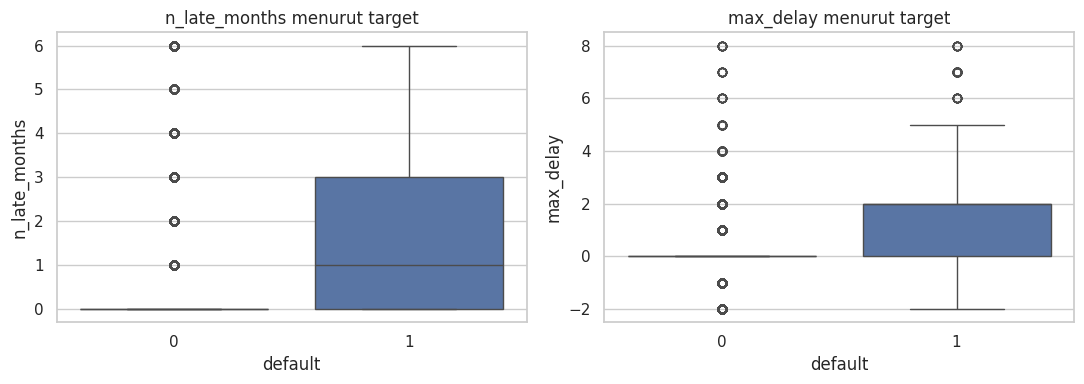

In [ ]:
def add_features(d):
    d = d.copy()
    d["n_late_months"] = (d[PAY_COLS] > 0).sum(axis=1)
    d["max_delay"]     = d[PAY_COLS].max(axis=1)
    d["utilization"]   = d["BILL_AMT1"] / d["LIMIT_BAL"]
    d["pay_ratio"]     = d[PAMT_COLS].sum(axis=1) / (d[BILL_COLS].clip(lower=0).sum(axis=1) + 1)
    d["avg_bill"]      = d[BILL_COLS].mean(axis=1)
    d["avg_pay_amt"]   = d[PAMT_COLS].mean(axis=1)
    return d

train_fe, test_fe = add_features(train_df), add_features(test_df)
X_train_fe, X_test_fe = train_fe.drop(columns=TARGET), test_fe.drop(columns=TARGET)

fe_corr = train_fe[NEW_FEATS + [TARGET]].corr()[TARGET].drop(TARGET).round(3)
R["fe_corr"] = {k: float(v) for k, v in fe_corr.items()}
print("Korelasi fitur baru dengan target (hanya data latih):")
display(fe_corr.to_frame("korelasi dgn default"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=TARGET, y="n_late_months", data=train_fe, ax=axes[0]); axes[0].set_title("n_late_months menurut target")
sns.boxplot(x=TARGET, y="max_delay", data=train_fe, ax=axes[1]); axes[1].set_title("max_delay menurut target")
plt.tight_layout(); plt.savefig("figures/05b_fitur_baru.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
# Preprocessor: transformasi log bertanda + scaling untuk fitur uang, scaling untuk fitur lain, one-hot untuk kategori
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

def build_preprocessor(use_fe=True):
    log_cols  = ["LIMIT_BAL"] + BILL_COLS + PAMT_COLS
    plain_num = ["AGE"] + PAY_COLS
    if use_fe:
        log_cols  = log_cols + ["utilization", "pay_ratio", "avg_bill", "avg_pay_amt"]
        plain_num = plain_num + ["n_late_months", "max_delay"]
    return ColumnTransformer([
        ("log_num", Pipeline([("imp", SimpleImputer(strategy="median")),
                              ("log", FunctionTransformer(signed_log, feature_names_out="one-to-one")),
                              ("sc", StandardScaler())]), log_cols),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), plain_num),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), LIST_KATEGORIK),
    ])

# Demonstrasi: di-fit hanya pada data latih, lalu diterapkan ke data uji
prep_demo = build_preprocessor(True)
Xtr_demo = prep_demo.fit_transform(X_train_fe)
Xte_demo = prep_demo.transform(X_test_fe)
names_demo = prep_demo.get_feature_names_out()
R["n_features_final"] = int(Xtr_demo.shape[1])
print("Bentuk data setelah preprocessing -> train:", Xtr_demo.shape, "| test:", Xte_demo.shape)
pd.DataFrame(Xtr_demo[:5], columns=names_demo).round(3).to_csv("results/contoh_data_setelah_preprocessing.csv", index=False)

# Dampak transformasi log pada kemiringan (data latih)
cols_sk = ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]
skew_tab = pd.DataFrame({"skewness sebelum": train_fe[cols_sk].skew(),
                         "skewness sesudah log": train_fe[cols_sk].apply(signed_log).skew()}).round(2)
R["skew_before_after"] = {i: [float(skew_tab.loc[i, "skewness sebelum"]), float(skew_tab.loc[i, "skewness sesudah log"])] for i in skew_tab.index}
display(skew_tab)
print("Catatan: transformasi log menurunkan besaran kemiringan secara umum, tetapi belum membuat distribusi benar-benar simetris "
      "(tagihan memuat banyak nilai nol dan negatif).")

Bentuk data setelah preprocessing -> train: (23972, 32) | test: (5993, 32)


,skewness sebelum,skewness sesudah log
LIMIT_BAL,1.00,-0.52
BILL_AMT1,2.64,-2.07
PAY_AMT1,15.62,-1.30


Catatan: transformasi log menurunkan besaran kemiringan secara umum, tetapi belum membuat distribusi benar-benar simetris (tagihan memuat banyak nilai nol dan negatif).


# F. Baseline dan Initial Candidate Models



In [ ]:
def make_pipe(clf, use_fe=True):
    return Pipeline([("prep", build_preprocessor(use_fe)), ("clf", clf)])

BASE = "Logistic Regression (BASELINE)"
DUMMY = "Dummy (mayoritas)"
MODELS = {
    DUMMY: DummyClassifier(strategy="most_frequent"),
    BASE: LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "LogReg + class_weight": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, class_weight="balanced", random_state=RANDOM_STATE),
    "KNN (k=25)": KNeighborsClassifier(n_neighbors=25, n_jobs=-1),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=20,
                                            class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_depth=5,
                                                           class_weight="balanced", random_state=RANDOM_STATE),
}
PERAN = {DUMMY: "pembanding trivial", BASE: "BASELINE"}
for n in MODELS:
    PERAN.setdefault(n, "kandidat")
pd.DataFrame({"Peran": PERAN, "Konfigurasi": {n: str(m) for n, m in MODELS.items()}}).to_csv("results/daftar_model.csv")
print("Model:", list(MODELS))

Model: ['Dummy (mayoritas)', 'Logistic Regression (BASELINE)', 'LogReg + class_weight', 'Decision Tree', 'KNN (k=25)', 'Random Forest', 'HistGradientBoosting']


# G. Evaluation Design



In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}

cv_rows, cv_raw = [], {}
for name, clf in MODELS.items():
    t0 = time.time()
    cv = cross_validate(make_pipe(clf), X_train_fe, y_train, cv=skf, scoring=SCORING, n_jobs=1, error_score="raise")
    cv_raw[name] = cv
    row = {"Model": name}
    for m in SCORING:
        row[m] = cv[f"test_{m}"].mean(); row[m + "_std"] = cv[f"test_{m}"].std()
    row["waktu_dtk"] = round(time.time() - t0, 1)
    cv_rows.append(row)
    print(f"{name:32s} Recall={row['recall']:.3f} F1={row['f1']:.3f} PR-AUC={row['pr_auc']:.3f} ({row['waktu_dtk']} dtk)")
cv_df = pd.DataFrame(cv_rows).set_index("Model")
cv_df.to_csv("results/cv_results.csv")

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.p

Dummy (mayoritas)                Recall=0.000 F1=0.000 PR-AUC=0.221 (0.8 dtk)
Logistic Regression (BASELINE)   Recall=0.319 F1=0.419 PR-AUC=0.510 (2.4 dtk)
LogReg + class_weight            Recall=0.625 F1=0.530 PR-AUC=0.505 (2.3 dtk)
Decision Tree                    Recall=0.645 F1=0.524 PR-AUC=0.524 (2.2 dtk)
KNN (k=25)                       Recall=0.354 F1=0.451 PR-AUC=0.505 (12.6 dtk)
Random Forest                    Recall=0.612 F1=0.544 PR-AUC=0.560 (50.8 dtk)
HistGradientBoosting             Recall=0.628 F1=0.537 PR-AUC=0.564 (5.4 dtk)


# H. Initial Results and Analysis

In [ ]:
# H1. Hasil validasi silang 5-fold (rata-rata ± simpangan baku)
cv_table = pd.DataFrame({m: [f"{cv_df.loc[n, m]:.3f} ± {cv_df.loc[n, m + '_std']:.3f}" for n in cv_df.index]
                         for m in SCORING}, index=cv_df.index)
cv_table.columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
cv_table.to_csv("results/cv_table.csv")
cv_table

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Dummy (mayoritas),0.779 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.221 ± 0.000
Logistic Regression (BASELINE),0.805 ± 0.006,0.613 ± 0.031,0.319 ± 0.010,0.419 ± 0.014,0.762 ± 0.011,0.510 ± 0.015
LogReg + class_weight,0.755 ± 0.006,0.461 ± 0.010,0.625 ± 0.010,0.530 ± 0.009,0.765 ± 0.011,0.505 ± 0.014
Decision Tree,0.740 ± 0.025,0.444 ± 0.032,0.645 ± 0.041,0.524 ± 0.015,0.772 ± 0.006,0.524 ± 0.010
KNN (k=25),0.809 ± 0.003,0.621 ± 0.019,0.354 ± 0.009,0.451 ± 0.005,0.762 ± 0.006,0.505 ± 0.013
Random Forest,0.773 ± 0.006,0.490 ± 0.012,0.612 ± 0.012,0.544 ± 0.011,0.787 ± 0.009,0.560 ± 0.010
HistGradientBoosting,0.760 ± 0.006,0.469 ± 0.009,0.628 ± 0.009,0.537 ± 0.009,0.788 ± 0.008,0.564 ± 0.011


In [ ]:
# H2. Selisih per fold terhadap baseline (fold yang sama): apakah perbaikan konsisten?
rows = []
for n in MODELS:
    if n in (BASE, DUMMY):
        continue
    r = {"Model": n}
    for m in ["recall", "f1", "pr_auc", "roc_auc"]:
        d = cv_raw[n][f"test_{m}"] - cv_raw[BASE][f"test_{m}"]
        r[f"selisih {m}"] = d.mean()
        r[f"fold lebih baik ({m})"] = f"{int((d > 0).sum())}/5"
    rows.append(r)
paired = pd.DataFrame(rows).set_index("Model").round(4)
paired.to_csv("results/selisih_per_fold_vs_baseline.csv")
display(paired)

,selisih recall,fold lebih baik (recall),selisih f1,fold lebih baik (f1),selisih pr_auc,fold lebih baik (pr_auc),selisih roc_auc,fold lebih baik (roc_auc)
Model,,,,,,,,
LogReg + class_weight,0.3056,5/5,0.1107,5/5,-0.0042,0/5,0.0034,5/5
Decision Tree,0.3264,5/5,0.1047,5/5,0.0145,5/5,0.0097,5/5
KNN (k=25),0.0354,5/5,0.0317,5/5,-0.0043,2/5,-0.0002,3/5
Random Forest,0.2932,5/5,0.1246,5/5,0.0499,5/5,0.0249,5/5
HistGradientBoosting,0.3088,5/5,0.1175,5/5,0.0542,5/5,0.0259,5/5


In [ ]:
# H3. Hasil pada data uji (dilatih pada seluruh data latih, dievaluasi sekali)
fitted, proba_test, test_rows = {}, {}, []
for name, clf in MODELS.items():
    pipe = make_pipe(clf).fit(X_train_fe, y_train)
    fitted[name] = pipe
    proba = pipe.predict_proba(X_test_fe)[:, 1]
    proba_test[name] = proba
    pred = (proba >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    test_rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred),
                      "Precision": precision_score(y_test, pred, zero_division=0),
                      "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                      "ROC-AUC": roc_auc_score(y_test, proba), "PR-AUC": average_precision_score(y_test, proba),
                      "TN": tn, "FP": fp, "FN": fn, "TP": tp})
test_df_res = pd.DataFrame(test_rows).set_index("Model")
test_df_res.round(4).to_csv("results/test_results.csv")
test_df_res.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,TN,FP,FN,TP
Model,,,,,,,,,,
Dummy (mayoritas),0.7787,0.0000,0.0000,0.0000,0.5000,0.2213,4667,0,1326,0
Logistic Regression (BASELINE),0.8068,0.6254,0.3160,0.4198,0.7555,0.5178,4416,251,907,419
LogReg + class_weight,0.7495,0.4508,0.6048,0.5166,0.7582,0.5124,3690,977,524,802
Decision Tree,0.7465,0.4471,0.6146,0.5176,0.7631,0.5150,3659,1008,511,815
KNN (k=25),0.8076,0.6137,0.3522,0.4475,0.7576,0.5012,4373,294,859,467
Random Forest,0.7712,0.4862,0.5980,0.5364,0.7752,0.5551,3829,838,533,793
HistGradientBoosting,0.7524,0.4563,0.6222,0.5265,0.7786,0.5559,3684,983,501,825


In [ ]:
# H4. TABEL HASIL EKSPERIMEN AWAL (gabungan: baseline, kandidat, validasi, metrik, hasil)
tabel = pd.DataFrame({
    "Peran": pd.Series(PERAN),
    "Fitur": "asli + 6 turunan",
    "Validasi": "5-fold stratified CV (train) + hold-out test 20%",
    "CV Recall": cv_table["Recall"], "CV Precision": cv_table["Precision"], "CV F1": cv_table["F1"],
    "CV ROC-AUC": cv_table["ROC-AUC"], "CV PR-AUC": cv_table["PR-AUC"], "CV Accuracy": cv_table["Accuracy"],
    "Test Recall": test_df_res["Recall"].round(3), "Test Precision": test_df_res["Precision"].round(3),
    "Test F1": test_df_res["F1"].round(3), "Test ROC-AUC": test_df_res["ROC-AUC"].round(3),
    "Test PR-AUC": test_df_res["PR-AUC"].round(3), "Test Accuracy": test_df_res["Accuracy"].round(3),
})
tabel.index.name = "Model"
tabel.to_csv("results/tabel_hasil_eksperimen_awal.csv")
with pd.option_context("display.width", 250):
    display(tabel)

,Peran,Fitur,Validasi,CV Recall,CV Precision,CV F1,CV ROC-AUC,CV PR-AUC,CV Accuracy,Test Recall,Test Precision,Test F1,Test ROC-AUC,Test PR-AUC,Test Accuracy
Model,,,,,,,,,,,,,,,
Dummy (mayoritas),pembanding trivial,asli + 6 turunan,5-fold stratified CV (train) + hold-out test 20%,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.221 ± 0.000,0.779 ± 0.000,0.000,0.000,0.000,0.500,0.221,0.779
Logistic Regression (BASELINE),BASELINE,asli + 6 turunan,5-fold stratified CV (train) + hold-out test 20%,0.319 ± 0.010,0.613 ± 0.031,0.419 ± 0.014,0.762 ± 0.011,0.510 ± 0.015,0.805 ± 0.006,0.316,0.625,0.420,0.755,0.518,0.807
LogReg + class_weight,kandidat,asli + 6 turunan,5-fold stratified CV (train) + hold-out test 20%,0.625 ± 0.010,0.461 ± 0.010,0.530 ± 0.009,0.765 ± 0.011,0.505 ± 0.014,0.755 ± 0.006,0.605,0.451,0.517,0.758,0.512,0.750
Decision Tree,kandidat,asli + 6 turunan,5-fold stratified CV (train) + hold-out test 20%,0.645 ± 0.041,0.444 ± 0.032,0.524 ± 0.015,0.772 ± 0.006,0.524 ± 0.010,0.740 ± 0.025,0.615,0.447,0.518,0.763,0.515,0.747
KNN (k=25),kandidat,asli + 6 turunan,5-fold stratified CV (train) + hold-out test 20%,0.354 ± 0.009,0.621 ± 0.019,0.451 ± 0.005,0.762 ± 0.006,0.505 ± 0.013,0.809 ± 0.003,0.352,0.614,0.448,0.758,0.501,0.808
Random Forest,kandidat,asli + 6 turunan,5-fold stratified CV (train) + hold-out test 20%,0.612 ± 0.012,0.490 ± 0.012,0.544 ± 0.011,0.787 ± 0.009,0.560 ± 0.010,0.773 ± 0.006,0.598,0.486,0.536,0.775,0.555,0.771
HistGradientBoosting,kandidat,asli + 6 turunan,5-fold stratified CV (train) + hold-out test 20%,0.628 ± 0.009,0.469 ± 0.009,0.537 ± 0.009,0.788 ± 0.008,0.564 ± 0.011,0.760 ± 0.006,0.622,0.456,0.526,0.779,0.556,0.752


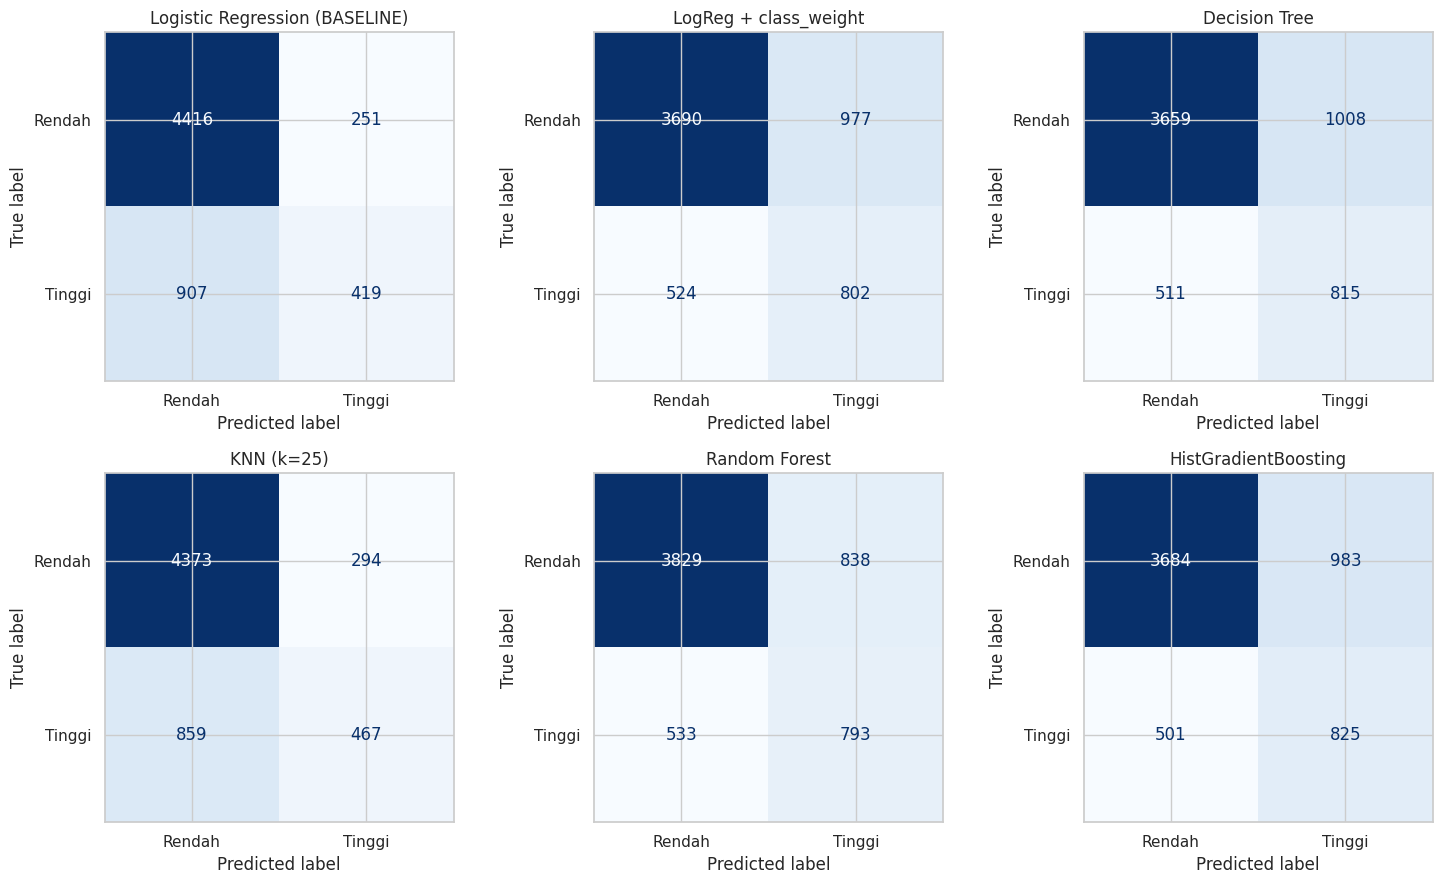

In [ ]:
# H5. Confusion matrix (data uji)
names_cm = [n for n in MODELS if n != DUMMY]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, n in zip(axes.ravel(), names_cm):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba_test[n] >= 0.5).astype(int),
        display_labels=["Rendah", "Tinggi"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(n)
plt.tight_layout(); plt.savefig("figures/06_confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

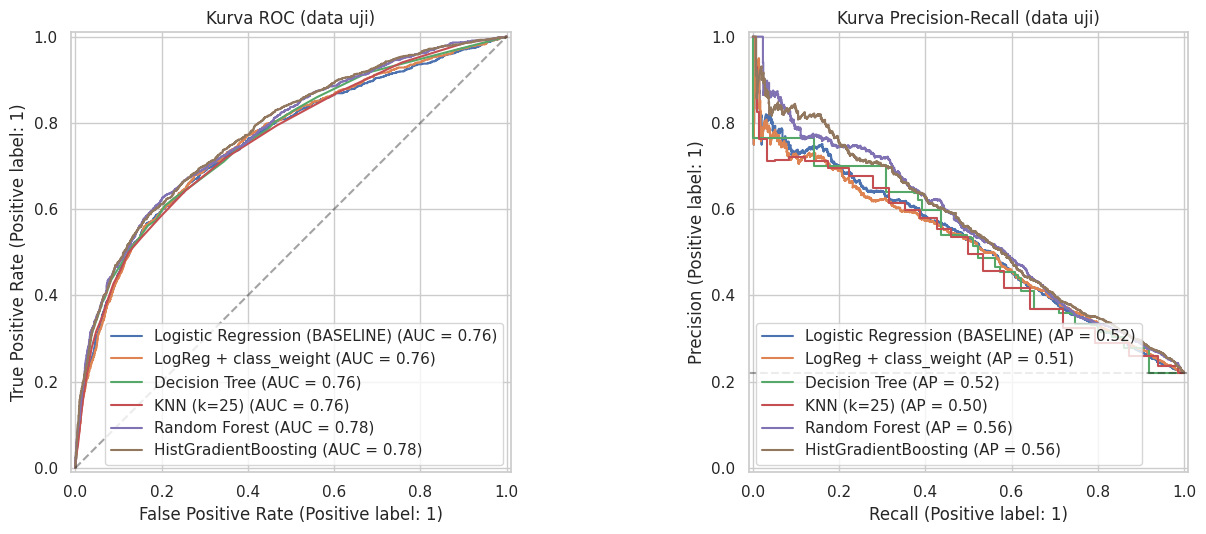

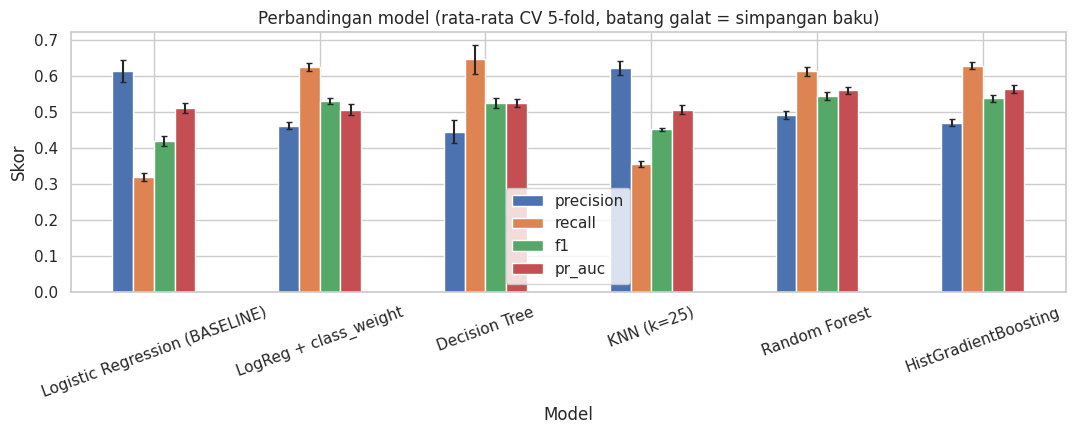

In [ ]:
# H6. Kurva ROC dan Precision-Recall (data uji)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for n in names_cm:
    RocCurveDisplay.from_predictions(y_test, proba_test[n], name=n, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba_test[n], name=n, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4); axes[0].set_title("Kurva ROC (data uji)")
axes[1].axhline(y_test.mean(), color="k", ls="--", alpha=0.4); axes[1].set_title("Kurva Precision-Recall (data uji)")
plt.tight_layout(); plt.savefig("figures/07_roc_pr.png", dpi=150, bbox_inches="tight"); plt.show()

# H7. Perbandingan metrik CV antar model
plot_df = cv_df.drop(index=DUMMY)[["precision", "recall", "f1", "pr_auc"]]
plot_df.plot(kind="bar", figsize=(11, 4.5), rot=20, yerr=cv_df.drop(index=DUMMY)[["precision_std", "recall_std", "f1_std", "pr_auc_std"]].values.T, capsize=2)
plt.title("Perbandingan model (rata-rata CV 5-fold, batang galat = simpangan baku)"); plt.ylabel("Skor")
plt.tight_layout(); plt.savefig("figures/08_perbandingan_cv.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
# H8. Ablation feature engineering: dengan vs tanpa fitur turunan (CV 5-fold, fold yang sama)
abl_rows = []
for name in [BASE, "Random Forest"]:
    for use_fe in [False, True]:
        Xa = X_train_fe if use_fe else X_train_fe.drop(columns=NEW_FEATS)
        cv = cross_validate(make_pipe(MODELS[name], use_fe), Xa, y_train, cv=skf,
                            scoring={"recall": "recall", "f1": "f1", "pr_auc": "average_precision", "roc_auc": "roc_auc"}, n_jobs=1)
        abl_rows.append({"Model": name, "Fitur turunan": "dengan" if use_fe else "tanpa",
                         "Recall": cv["test_recall"].mean(), "F1": cv["test_f1"].mean(),
                         "PR-AUC": cv["test_pr_auc"].mean(), "ROC-AUC": cv["test_roc_auc"].mean()})
abl = pd.DataFrame(abl_rows).set_index(["Model", "Fitur turunan"]).round(4)
abl.to_csv("results/ablasi_feature_engineering.csv")
R["ablation"] = {f"{m}|{f}": {k: float(v) for k, v in abl.loc[(m, f)].items()} for m, f in abl.index}
abl

Recall      F1  PR-AUC  ROC-AUC
Model                          Fitur turunan                                 
Logistic Regression (BASELINE) tanpa          0.2477  0.3611  0.5033   0.7483
                               dengan         0.3190  0.4194  0.5097   0.7621
Random Forest                  tanpa          0.6052  0.5477  0.5574   0.7839
                               dengan         0.6122  0.5441  0.5596   0.7870

In [ ]:
# H9. Temuan awal (dihitung otomatis dari tabel di atas)
cvd = cv_df.drop(index=DUMMY)
R["cv"] = {n: {m: float(cv_df.loc[n, m]) for m in SCORING} | {m + "_std": float(cv_df.loc[n, m + "_std"]) for m in SCORING} for n in cv_df.index}
R["test"] = {n: {k: float(v) for k, v in test_df_res.loc[n].items()} for n in test_df_res.index}
R["dummy_acc_test"] = float(test_df_res.loc[DUMMY, "Accuracy"])

print("TEMUAN HASIL EKSPERIMEN AWAL")

# 1. Dummy dan baseline
print(f"1. Dummy classifier mencapai Accuracy {R['dummy_acc_test']:.3f} dengan Recall 0 -> Accuracy tidak bisa dipakai sendirian. "
      f"Baseline LogReg: Accuracy {test_df_res.loc[BASE, 'Accuracy']:.3f} tetapi Recall hanya {cv_df.loc[BASE, 'recall']:.3f} (CV) / {test_df_res.loc[BASE, 'Recall']:.3f} (test).")

# 2. Model terbaik per metrik
best = {m: cvd[m].idxmax() for m in ["pr_auc", "roc_auc", "f1", "recall", "precision", "accuracy"]}
R["best_cv"] = best
print("2. Model terbaik per metrik (CV): " + "; ".join(f"{m}: {n} ({cvd.loc[n, m]:.3f})" for m, n in best.items()))

# 3. Konsistensi perbaikan PR-AUC terhadap baseline di setiap fold (fold yang sama)
wins, fold_wins = [], {}
for n in cvd.index:
    if n == BASE: continue
    d = cv_raw[n]["test_pr_auc"] - cv_raw[BASE]["test_pr_auc"]
    fold_wins[n] = int((d > 0).sum())
    if (d > 0).all(): wins.append(n)
R["konsisten_lebih_baik_prauc"] = wins
R["fold_menang_prauc"] = fold_wins
print("3. Model yang lebih baik dari baseline pada PR-AUC di semua 5 fold: " + (", ".join(wins) if wins else "tidak ada"))
print("   Jumlah fold yang lebih baik dari baseline (PR-AUC): " + "; ".join(f"{n} {k}/5" for n, k in fold_wins.items()))
for n in cvd.index:
    if n == BASE: continue
    dr = cv_df.loc[n, "recall"] - cv_df.loc[BASE, "recall"]
    dp = cv_df.loc[n, "precision"] - cv_df.loc[BASE, "precision"]
    df1 = cv_df.loc[n, "f1"] - cv_df.loc[BASE, "f1"]
    dpr = cv_df.loc[n, "pr_auc"] - cv_df.loc[BASE, "pr_auc"]
    print(f"   - {n}: Recall {dr:+.3f}, Precision {dp:+.3f}, F1 {df1:+.3f}, PR-AUC {dpr:+.3f} terhadap baseline (CV).")

# 4. Konsistensi CV vs hold-out test
gap = max(abs(cv_df.loc[n, "pr_auc"] - test_df_res.loc[n, "PR-AUC"]) for n in cvd.index)
print(f"4. Konsistensi CV vs test: selisih PR-AUC terbesar {gap:.3f} -> hasil CV dan hold-out sejalan." if gap < 0.03 else
      f"4. Konsistensi CV vs test: selisih PR-AUC terbesar {gap:.3f} -> perlu dicermati.")

# 5. Ablation fitur turunan
a1, a0 = abl.loc[(BASE, "dengan")], abl.loc[(BASE, "tanpa")]
r1, r0 = abl.loc[("Random Forest", "dengan")], abl.loc[("Random Forest", "tanpa")]
print(f"5. Ablation fitur turunan - LogReg: Recall {a0['Recall']:.3f} -> {a1['Recall']:.3f}, F1 {a0['F1']:.3f} -> {a1['F1']:.3f}, PR-AUC {a0['PR-AUC']:.3f} -> {a1['PR-AUC']:.3f}; "
      f"Random Forest: Recall {r0['Recall']:.3f} -> {r1['Recall']:.3f}, F1 {r0['F1']:.3f} -> {r1['F1']:.3f}, PR-AUC {r0['PR-AUC']:.3f} -> {r1['PR-AUC']:.3f}.")

# 6. Seberapa jelas perbedaan antar model (dibandingkan simpangan baku antar fold)
top2 = cvd["pr_auc"].sort_values(ascending=False).head(2)
gap_top = top2.iloc[0] - top2.iloc[1]
std_mean = cvd["pr_auc_std"].mean()
gains = [cvd.loc[m, "pr_auc"] - cvd.loc[BASE, "pr_auc"] for m in top2.index]
verdict = "belum bisa dibedakan" if gap_top < std_mean else "terpisah lebih dari simpangan baku"
print(f"6. Dua model PR-AUC tertinggi: {top2.index[0]} ({top2.iloc[0]:.3f}) dan {top2.index[1]} ({top2.iloc[1]:.3f}); "
      f"selisih keduanya {gap_top:.3f} vs simpangan baku CV sekitar {std_mean:.3f} -> {verdict}. "
      f"Terhadap baseline, keduanya unggul {min(gains):.3f} sampai {max(gains):.3f} PR-AUC "
      f"(sekitar {min(gains) / std_mean:.1f}-{max(gains) / std_mean:.1f}x simpangan baku).")

# 7. Catatan penting untuk membaca Recall dan Precision
print("7. Catatan: Decision Tree, Random Forest, dan HistGradientBoosting juga memakai class_weight, sehingga kenaikan Recall dan penurunan Precision mereka "
      "tercampur efek pergeseran ambang. Kualitas pemeringkatan dibandingkan lewat PR-AUC dan ROC-AUC.")

# 8. Verdict terhadap kriteria keberhasilan (Bagian A): lebih baik dari baseline di 5/5 fold pada Recall, F1, dan PR-AUC
print("8. VERDICT KRITERIA KEBERHASILAN (lebih baik dari baseline di 5/5 fold pada Recall, F1, dan PR-AUC)")
verdict_kriteria = {}
for n in cvd.index:
    if n == BASE:
        continue
    ok = all(((cv_raw[n][f"test_{m}"] - cv_raw[BASE][f"test_{m}"]) > 0).all() for m in ["recall", "f1", "pr_auc"])
    verdict_kriteria[n] = bool(ok)
    print(f"   - {n}: {'MEMENUHI' if ok else 'TIDAK memenuhi'}")
R["verdict_kriteria"] = verdict_kriteria


TEMUAN HASIL EKSPERIMEN AWAL
1. Dummy classifier mencapai Accuracy 0.779 dengan Recall 0 -> Accuracy tidak bisa dipakai sendirian. Baseline LogReg: Accuracy 0.807 tetapi Recall hanya 0.319 (CV) / 0.316 (test).
2. Model terbaik per metrik (CV): pr_auc: HistGradientBoosting (0.564); roc_auc: HistGradientBoosting (0.788); f1: Random Forest (0.544); recall: Decision Tree (0.645); precision: KNN (k=25) (0.621); accuracy: KNN (k=25) (0.809)
3. Model yang lebih baik dari baseline pada PR-AUC di semua 5 fold: Decision Tree, Random Forest, HistGradientBoosting
   Jumlah fold yang lebih baik dari baseline (PR-AUC): LogReg + class_weight 0/5; Decision Tree 5/5; KNN (k=25) 2/5; Random Forest 5/5; HistGradientBoosting 5/5
   - LogReg + class_weight: Recall +0.306, Precision -0.152, F1 +0.111, PR-AUC -0.004 terhadap baseline (CV).
   - Decision Tree: Recall +0.326, Precision -0.169, F1 +0.105, PR-AUC +0.014 terhadap baseline (CV).
   - KNN (k=25): Recall +0.035, Precision +0.008, F1 +0.032, PR-AUC -

**Analisis hasil awal.**
- **Baseline cenderung "aman" ke kelas mayoritas.** Pada ambang 0,5, Logistic Regression standar memiliki Accuracy tinggi (0,807 pada data uji) tetapi Recall rendah (0,316): banyak nasabah yang sebenarnya gagal bayar lolos (*false negative* pada confusion matrix: 907 dari 1.326). Ini sesuai dengan hipotesis dari EDA bahwa ketidakseimbangan kelas memengaruhi keputusan pada ambang bawaan.
- **Menangani imbalance mengubah *trade-off*, bukan kualitas pemeringkatan.** `class_weight="balanced"` menaikkan Recall secara besar (0,319 menjadi 0,625 pada CV) dengan mengorbankan Precision dan Accuracy, sedangkan ROC-AUC dan PR-AUC nyaris tidak berubah (PR-AUC -0,004, lebih baik di 0 dari 5 fold). Jadi sebagian besar "perbaikan" Recall berasal dari pergeseran titik operasi, bukan dari model yang lebih pandai membedakan kelas.
- **Model non-linear (Random Forest, HistGradientBoosting) memberi PR-AUC dan ROC-AUC tertinggi.** HGB (0,564) dan RF (0,560) belum dapat dibedakan (selisih 0,004, lebih kecil dari simpangan baku sekitar 0,012). Keduanya unggul sekitar 0,036-0,040 PR-AUC atas Decision Tree dan sekitar 0,05 atas baseline, di 5 dari 5 fold. Pemilihan model final tetap ditunda ke tahap lanjutan.
- **KNN** memiliki Accuracy dan Precision tertinggi tetapi Recall rendah (0,354, mendekati baseline). Waktu CV-nya paling lama di antara model non-ensemble
- **Fitur turunan (ablation H8):** pada Logistic Regression, Recall naik 0,248 menjadi 0,319 (+0,071) dan F1 0,361 menjadi 0,419 (+0,058), tetapi PR-AUC hanya naik 0,006 (lebih kecil dari simpangan baku 0,015), sehingga kemampuan memeringkat risiko hampir tidak berubah. Pada Random Forest perubahannya sangat kecil (Recall +0,007, F1 -0,004). Fitur turunan terutama menggeser titik operasi pada model linear.
- **Kehati-hatian pada Recall:** Recall tertinggi Decision Tree (0,645 ± 0,041) tidak dapat dibedakan dari HGB (0,628), LogReg + class_weight (0,625), dan RF (0,612) karena simpangan bakunya besar.
- **Kriteria keberhasilan (Bagian A):** Recall dan F1 lebih baik dari baseline di 5 dari 5 fold untuk kelima kandidat. Untuk PR-AUC hanya Decision Tree, Random Forest, dan HistGradientBoosting yang unggul di 5 dari 5 fold; LogReg + class_weight (0 dari 5) dan KNN (2 dari 5) tidak memenuhi kriteria pada PR-AUC. Keluaran otomatis ada pada temuan nomor 8 di atas.
- **Konsistensi:** hasil validasi silang dan hasil hold-out sejalan (lihat temuan nomor 4 di atas).

**Keterbatasan.**
1. Ambang keputusan masih 0,5 untuk semua model, sehingga perbandingan Recall dan Precision sebagian mencerminkan perbedaan titik operasi (efek `class_weight`), bukan murni kualitas model. Perbandingan PR-AUC dan ROC-AUC tidak terpengaruh ambang.
2. Hyperparameter model kandidat tetap dan belum di-tuning; peringkat antar model bisa berubah setelah tuning.
3. Hold-out test hanya satu pembagian (±1.300 kasus positif). CV memberi gambaran stabilitas, tetapi data uji belum dibuat ulang dengan pembagian lain.
4. Data hanya satu bank di Taiwan tahun 2005 dengan makna `PAY_* = -2/0` yang tidak terdokumentasi.
5. Belum ada analisis kesalahan rinci, interpretabilitas, atau pengecekan keadilan antar kelompok demografis.

**Hal yang masih perlu diperbaiki:** lihat rencana lanjutan di bagian I.


# I. Documentation and Next Plan

## Catatan eksperimen
- **Lingkungan:** versi Python dan library dicetak pada sel terakhir dan disimpan di `results/summary.json`.
- **Reproduksibilitas:** `random_state=42` untuk split, CV, dan model; urutan baris data sama setiap kali diunduh dari UCI.
- **Alur eksperimen:** unduh data (tautan UCI) -> pembersihan aturan tetap + hapus duplikat -> split 80:20 stratified -> fitur turunan -> pipeline preprocessing -> 7 model dievaluasi dengan 5-fold stratified CV pada data latih -> pelatihan ulang pada seluruh data latih dan evaluasi satu kali pada data uji -> ablation fitur turunan.
- **Keluaran yang dapat ditelusuri:** `results/tabel_hasil_eksperimen_awal.csv` (tabel hasil utama), `results/cv_results.csv`, `results/test_results.csv`, `results/selisih_per_fold_vs_baseline.csv`, `results/ablasi_feature_engineering.csv`, `results/summary.json`, dan `figures/*.png`. Angka di laporan PDF harus disalin dari file-file ini.
- **Pembagian kerja anggota:** lihat tabel di bawah (setiap anggota harus memahami bagian yang dikerjakan).



In [ ]:
# Simpan ringkasan dan jejak lingkungan agar hasil dapat ditelusuri
import shutil
R["env"] = {"python": platform.python_version(), "sklearn": sklearn.__version__, "pandas": pd.__version__,
            "numpy": np.__version__, "random_state": RANDOM_STATE}
with open("results/summary.json", "w") as f:
    json.dump(R, f, indent=2, default=str)
print("Tersimpan: results/summary.json, results/*.csv, figures/*.png")
print(R["env"])
print("\nFile di results/:", sorted(os.listdir("results")))
print("File di figures/:", sorted(os.listdir("figures")))

# Arsip semua keluaran (opsional, untuk diunduh / dilampirkan ke pengumpulan)
shutil.make_archive("keluaran_milestone1", "zip", ".", "results")
print("\nArsip hasil: keluaran_milestone1.zip")

Tersimpan: results/summary.json, results/*.csv, figures/*.png
{'python': '3.13.18', 'sklearn': '1.6.1', 'pandas': '2.2.3', 'numpy': '2.4.6', 'random_state': 42}

File di results/: ['ablasi_feature_engineering.csv', 'contoh_data_setelah_preprocessing.csv', 'cv_results.csv', 'cv_table.csv', 'daftar_model.csv', 'outlier_summary.csv', 'selisih_per_fold_vs_baseline.csv', 'summary.json', 'tabel_hasil_eksperimen_awal.csv', 'test_results.csv', 'tipe_data_fitur.csv']
File di figures/: ['01_distribusi_target.png', '02_risiko_per_demografi.png', '03_risiko_per_pay1.png', '04_distribusi_fitur.png', '05_korelasi.png', '05b_fitur_baru.png', '06_confusion_matrix.png', '07_roc_pr.png', '08_perbandingan_cv.png']

Arsip hasil: keluaran_milestone1.zip
